# Fintual: Fintual Card
Integrantes: Iair Chistik, Francisco Cisternas y Agustín Rosales

In [1]:
# 1. Manipulación de datos y visualización
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 2. Estadística y distancias (Parte II y Parte III)
from scipy import stats
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
# 3. Preprocesamiento, Clustering y Posicionamiento (scikit-learn >= 1.8)
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
# 4. Configuración de formato y gráficos
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
sns.set_theme(style="whitegrid")
print(f"Versión de scikit-learn: {sklearn.__version__}")

Versión de scikit-learn: 1.9.1


## Parte 2

In [2]:
# Cargar las base de datos 
usuarios = pd.read_csv("fintual_users_dataset_2026.csv")
caracteristicas = pd.read_csv("user_demographics_2026.csv")
fintual_percepcion = pd.read_csv("fintual_perception_dataset_2026.csv")
# Resumen rápido de dimensiones y clientes únicos por tabla
base_datos = {
    "usuarios (comportamiento)": usuarios,
    "caracteristicas (demografía)": caracteristicas,
    "fintual_percepcion (encuesta)": fintual_percepcion
}
resumen_tablas = pd.DataFrame([
    {
        "Tabla": nombre,
        "Filas": df.shape[0],
        "Columnas": df.shape[1],
        "user_id únicos": df["user_id"].nunique(),
        "Filas duplicadas (exactas)": df.duplicated().sum()
    }
    for nombre, df in base_datos.items()
])
display(resumen_tablas)

,Tabla,Filas,Columnas,user_id únicos,Filas duplicadas (exactas)
0,usuarios (comportamiento),12025,6,12000,25
1,caracteristicas (demografía),12000,11,12000,0
2,fintual_percepcion (encuesta),21000,12,3000,0


## Parte 2.1: Auditoría de calidad de datos y análisis exploratorio 

In [3]:
# Estadisticas descriptivas y diagnostico en usuarios
variables_obj = [col for col in usuarios.columns if col != "user_id"]
desc_bruto = usuarios[variables_obj].describe().T
desc_bruto["nulos"] = usuarios[variables_obj].isna().sum()
desc_bruto["% nulos"] = (usuarios[variables_obj].isna().mean() * 100).round(2)
display(desc_bruto[["count", "nulos", "% nulos", "mean", "std", "min", "25%", "50%", "75%", "max"]])

,count,nulos,% nulos,mean,std,min,25%,50%,75%,max
age,"11,840.00",185,1.54,33.61,10.17,0.00,25.00,33.00,40.00,150.00
total_invested,"12,025.00",0,0.00,"8,106,127.96","13,929,064.99","15,500.00","302,300.00","2,824,300.00","9,637,000.00","239,386,000.00"
risk_tolerance,"11,647.00",378,3.14,3.22,1.21,0.00,2.00,3.00,4.00,5.00
months_active,"12,025.00",0,0.00,32.54,22.28,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"11,581.00",444,3.69,20.97,10.01,1.00,13.00,21.00,29.00,47.00


In [4]:
# Paso 1 de limpieza: Eliminar los 25 duplicados
total_duplicados  = usuarios.duplicated(subset="user_id").sum()
usuarios_copia = usuarios.drop_duplicates(subset="user_id").reset_index(drop=True)
print(f"Registros duplicados eliminados en 'usuarios': {total_duplicados} -> Quedan {len(usuarios_copia)} clientes únicos.")

Registros duplicados eliminados en 'usuarios': 25 -> Quedan 12000 clientes únicos.


In [5]:
# Paso 2 de auditoria: Encontrar valoores fuera de rango
edades_fuera_rango = usuarios_copia[usuarios_copia["age"].notna() & ~usuarios_copia["age"].between(18, 110)]
riesgo_fuera_rango = usuarios_copia[usuarios_copia["risk_tolerance"].notna() & ~usuarios_copia["risk_tolerance"].between(1, 5)]

print(f"\nEdades fuera de rango legal/biológico [18, 110]: {len(edades_fuera_rango)} casos")
print("Valores encontrados en 'age' fuera de rango:", sorted(edades_fuera_rango["age"].tolist()))
print(f"\nTolerancia al riesgo fuera de escala [1, 5]: {len(riesgo_fuera_rango)} casos (todos con valor = 0.0)")


Edades fuera de rango legal/biológico [18, 110]: 15 casos
Valores encontrados en 'age' fuera de rango: [0.0, 3.0, 7.0, 17.0, 17.0, 17.0, 17.0, 17.0, 17.0, 17.0, 17.0, 17.0, 112.0, 134.0, 150.0]

Tolerancia al riesgo fuera de escala [1, 5]: 70 casos (todos con valor = 0.0)


Patron en TOLERANCIA, los faltantes se concentran en clientes se concentran en clientes mas jovenes y nuevos

In [6]:
# 1. Clasificamos cada variable según su estado (Válido, Nulo o Fuera de rango) para comparar perfiles ()
estado_edad = np.where(usuarios_copia["age"].isna(), "Nulo (184)",
              np.where(~usuarios_copia["age"].between(18, 110), "Fuera de rango (15)", "Válido (11.801)"))
estado_riesgo = np.where(usuarios_copia["risk_tolerance"].isna(), "Nulo (377)",
                np.where(~usuarios_copia["risk_tolerance"].between(1, 5), "Fuera de rango (70)", "Válido (11.553)"))
estado_sesiones = np.where(usuarios_copia["app_sessions_month"].isna(), "Nulo (442)", "Válido (11.558)")
print("Patron en EDAD, los faltantes se concentran en clientes antiguos y de altos montos")
display(usuarios_copia.groupby(estado_edad)[["months_active", "total_invested", "app_sessions_month", "risk_tolerance"]].mean().round(2))
print("Patron en TOLERANCIA, los faltantes se concentran en clientes mas jovenes y nuevos")
display(usuarios_copia.groupby(estado_riesgo)[["age", "months_active", "total_invested", "app_sessions_month"]].mean().round(2))
print("Patrón en SESIONES APP, no se concentran en ningun tipo de cliente en especifico:")
display(usuarios_copia.groupby(estado_sesiones)[["age", "months_active", "total_invested", "risk_tolerance"]].mean().round(2))

Patron en EDAD, los faltantes se concentran en clientes antiguos y de altos montos


,months_active,total_invested,app_sessions_month,risk_tolerance
Fuera de rango (15),40.73,"12,974,206.67",19.86,3.53
Nulo (184),51.15,"17,586,988.04",21.80,3.32
Válido (11.801),32.26,"7,957,956.44",20.96,3.22


Patron en TOLERANCIA, los faltantes se concentran en clientes mas jovenes y nuevos


,age,months_active,total_invested,app_sessions_month
Fuera de rango (70),33.32,30.73,"7,579,897.14",20.78
Nulo (377),28.60,19.59,"4,507,414.85",24.28
Válido (11.553),33.77,32.99,"8,232,716.58",20.87


Patrón en SESIONES APP, no se concentran en ningun tipo de cliente en especifico:


,age,months_active,total_invested,risk_tolerance
Nulo (442),32.84,31.45,"7,661,805.43",3.27
Válido (11.558),33.64,32.60,"8,129,083.30",3.22


In [7]:
# A) Edad (184 nulos + 15 fuera de rango = 199 casos): Como los nulos se concentran en clientes con 51 meses de antigüedad, imputamos mediana condicional:
edad_valida = usuarios_copia["age"].between(18, 110)
mediana_edad_antiguos = usuarios_copia.loc[edad_valida & (usuarios_copia["months_active"] >= 50), "age"].median()
mediana_edad_general  = usuarios_copia.loc[edad_valida, "age"].median()                                           
imputar_edad = ~edad_valida
usuarios_copia.loc[imputar_edad, "age"] = np.where(
    usuarios_copia.loc[imputar_edad, "months_active"] >= 50,
    mediana_edad_antiguos,
    mediana_edad_general
)

# B) Tolerancia al riesgo (377 nulos + 70 en cero = 447 casos): Se imputa la mediana de la escala válida 1 a 5:
riesgo_valido = usuarios_copia["risk_tolerance"].between(1, 5)
mediana_riesgo = usuarios_copia.loc[riesgo_valido, "risk_tolerance"].median()
usuarios_copia.loc[~riesgo_valido, "risk_tolerance"] = mediana_riesgo

# C) Sesiones mensuales en la app (442 nulos): Al ser aleatorio (MCAR), se imputa con la mediana general (21.0 sesiones/mes)
mediana_sesiones = usuarios_copia["app_sessions_month"].median()  # 21.0
usuarios_copia["app_sessions_month"] = usuarios_copia["app_sessions_month"].fillna(mediana_sesiones)
print("\n Verificación post-limpieza de 'usuarios_copia' (0 nulos, rangos corregidos)")
display(usuarios_copia[variables_obj].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])


 Verificación post-limpieza de 'usuarios_copia' (0 nulos, rangos corregidos)


,count,mean,std,min,25%,50%,75%,max
age,"12,000.00",33.70,9.98,18.00,25.00,33.00,41.00,67.00
total_invested,"12,000.00","8,111,871.90","13,938,875.54","15,500.00","302,925.00","2,825,000.00","9,642,425.00","239,386,000.00"
risk_tolerance,"12,000.00",3.23,1.17,1.00,2.00,3.00,4.00,5.00
months_active,"12,000.00",32.56,22.29,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"12,000.00",20.98,9.82,1.00,13.00,21.00,29.00,47.00


In [8]:
# Estadísticas descriptivas y diagnóstico en caracteristicas
variables_caract = [col for col in caracteristicas.columns if col != "user_id"]
desc_caract = caracteristicas[variables_caract].describe(include="all").T
desc_caract["nulos"] = caracteristicas[variables_caract].isna().sum()
desc_caract["% nulos"] = (caracteristicas[variables_caract].isna().mean() * 100).round(2)
display(desc_caract[["count", "nulos", "% nulos", "unique", "top", "freq", "mean", "std", "min", "25%", "50%", "75%", "max"]])

,count,nulos,% nulos,unique,top,freq,mean,std,min,25%,50%,75%,max
region,11881,119,0.99,16,Metropolitana de Santiago,6830,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,11772,228,1.90,3,Masculino,6204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tramo_ingreso,11009,991,8.26,5,$1.200.001 - $2.500.000,3059,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ocupacion,12000,0,0.00,5,Dependiente,7707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
banco_principal,12000,0,0.00,12,Banco de Chile,2340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tiene_tarjeta_credito,12000,0,0.00,2,Sí,7989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_tarjetas_credito,"12,000.00",0,0.00,NaN,NaN,NaN,1.20,1.07,0.00,0.00,1.00,2.00,4.00
billetera_digital_principal,12000,0,0.00,5,Ninguna,4444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gasto_mensual_tarjetas_clp,"12,000.00",0,0.00,NaN,NaN,NaN,"1,155,643.58","1,046,950.30","48,000.00","440,000.00","848,000.00","1,519,000.00","14,602,000.00"
interes_fintual_card,"8,607.00",3393,28.28,NaN,NaN,NaN,3.58,1.08,1.00,3.00,4.00,4.00,5.00


#### Datos para imputar:
- Como genero tiene una opcion de "Otro/No declara" lo imputare con ella ya que es un MCAR, la gente se habra olvidado al responderla porque si se representa con otro genero o no queria declarlo estaba la opcion. 
- Para la region, primero quiero comprobar la region de los usuarios de fintual. Si los usuarios se concentran en un 90% en un region, imputare con ella porque de cada 100 clientes, solo 10 matematicamente hablando seran de otra region y en una base de datos de 12000 pasa piola. Como se comprobo en la tabla de abajo, la region top es santiago con un 56.92% por lo que prefiero imputar con "Sin dato" para no alterar los datos de una manera pobre. Podria aplicar otras tecnica como interpolacion, pero no vale la pena en nuestra opinion.
- Para tramo ingreso, es una variable sensible, o sea, MNAR. Fue un decision propia no querer contestarla, por lo que se prefiere imputar con no declara
- 'interes_fintual_card' (3.393 nulos, 28,28%) se mantiene tal cual para no alterar de manera artifical los datos de interes sobre la tarjeta y porque su dato en python es numerico.

In [9]:
# Conteo y porcentaje de clientes por región
tabla_regiones = pd.DataFrame({
    "Clientes": caracteristicas["region"].value_counts(dropna=False),
    "%": (caracteristicas["region"].value_counts(normalize=True, dropna=False) * 100).round(2)
})
display(tabla_regiones)

,Clientes,%
region,,
Metropolitana de Santiago,6830,56.92
Valparaíso,1208,10.07
Biobío,848,7.07
Antofagasta,422,3.52
Maule,422,3.52
O'Higgins,400,3.33
Araucanía,368,3.07
Coquimbo,328,2.73
Los Lagos,327,2.72


In [10]:
# Paso 3: Tratmiento de los nulos en caracteristicas
caracteristicas_copia = caracteristicas.copy()

# Cambiar los valores nulos segun lo que corresponda
caracteristicas_copia["genero"] = caracteristicas_copia["genero"].fillna("Otro / Prefiere no decir")  
caracteristicas_copia["region"] = caracteristicas_copia["region"].fillna("Sin dato")      
caracteristicas_copia["tramo_ingreso"] = caracteristicas_copia["tramo_ingreso"].fillna("No declara") 

# Verificamos si quienes no respondieron la encuesta in-app son distintos a quienes sí respondieron:
df_completo = usuarios_copia.merge(caracteristicas_copia, on="user_id", how="left")
df_completo["respondio_interes"] = np.where(df_completo["interes_fintual_card"].notna(), "Respondió", "No respondió")

print("Comparación entre quienes respondieron y NO respondieron 'interes_fintual_card'")
display(df_completo.groupby("respondio_interes")[["age", "months_active", "total_invested", "gasto_mensual_tarjetas_clp"]].mean().round(2))

Comparación entre quienes respondieron y NO respondieron 'interes_fintual_card'


,age,months_active,total_invested,gasto_mensual_tarjetas_clp
respondio_interes,,,,
No respondió,33.82,33.06,"8,118,454.26","1,162,691.42"
Respondió,33.65,32.36,"8,109,277.04","1,152,865.23"


Observando la tabla podemos detectar que los clientes que si respondieron no difieren de manera significativa con los que no respondieron

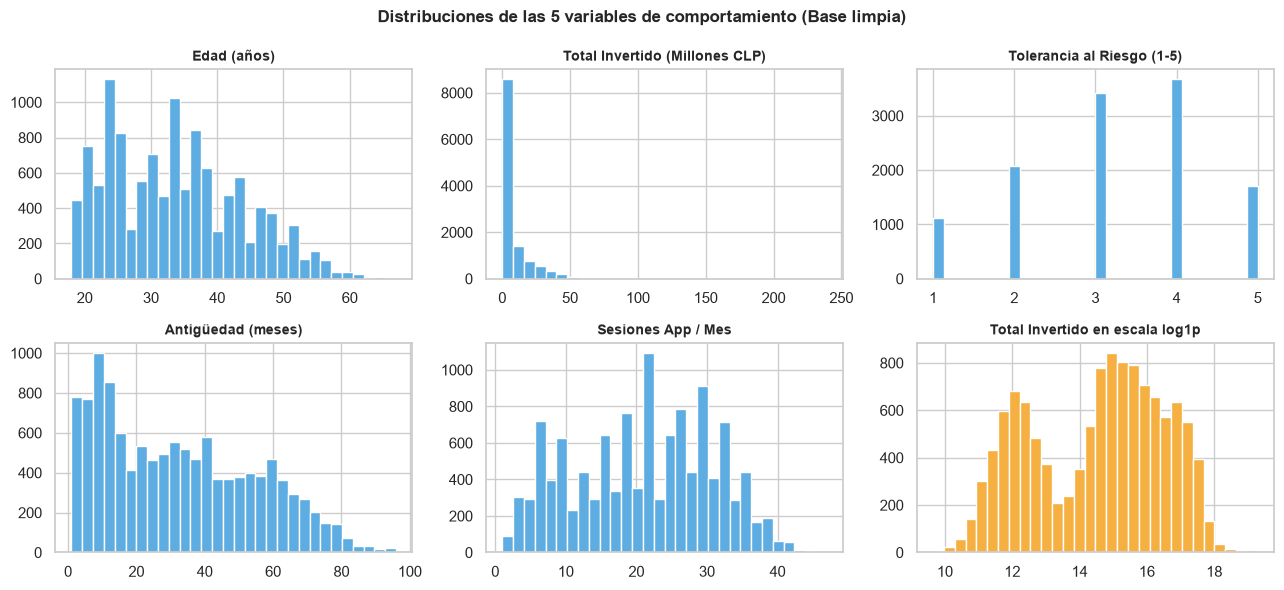

In [11]:
# 2. Histogramas de las 5 variables + comparación de 'total_invested' con log1p
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
nombres_esp = {
    "age": "Edad (años)",
    "total_invested": "Total Invertido (Millones CLP)",
    "risk_tolerance": "Tolerancia al Riesgo (1-5)",
    "months_active": "Antigüedad (meses)",
    "app_sessions_month": "Sesiones App / Mes"
}
for ax, col in zip(axes.flatten()[:5], variables_obj):
    serie = usuarios_copia[col] / 1_000_000 if col == "total_invested" else usuarios_copia[col]
    ax.hist(serie, bins=30, color="#5dade2", edgecolor="white")
    ax.set_title(nombres_esp[col], fontsize=10, fontweight="bold")
# Sexto panel: Total invertido transformado con log1p
axes[1, 2].hist(np.log1p(usuarios_copia["total_invested"]), bins=30, color="#f5b041", edgecolor="white")
axes[1, 2].set_title("Total Invertido en escala log1p", fontsize=10, fontweight="bold")
plt.suptitle("Distribuciones de las 5 variables de comportamiento (Base limpia)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

C:\Users\20fac\AppData\Local\Temp\ipykernel_16640\763308518.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax1.boxplot(usuarios_copia["total_invested"] / 1_000_000, vert=False, widths=0.5, patch_artist=True,
C:\Users\20fac\AppData\Local\Temp\ipykernel_16640\763308518.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax2.boxplot(np.log1p(usuarios_copia["total_invested"]), vert=False, widths=0.5, patch_artist=True,


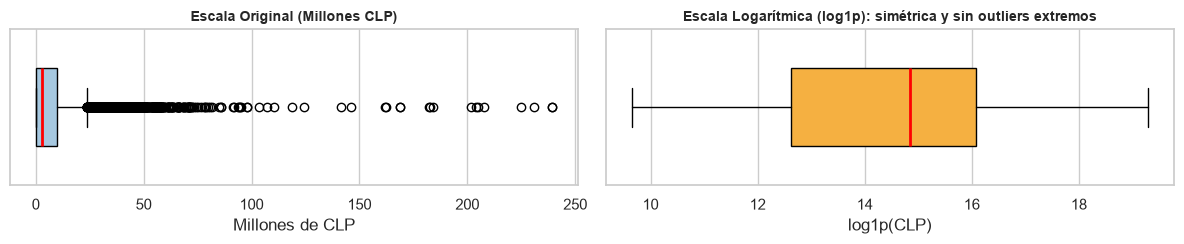

In [12]:
# 3. Boxplot comparativo: Total Invertido en CLP vs. Escala Logarítmica (log1p)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 2.6))
ax1.boxplot(usuarios_copia["total_invested"] / 1_000_000, vert=False, widths=0.5, patch_artist=True,
            boxprops=dict(facecolor="#a6c8e0"), medianprops=dict(color="red", linewidth=2))
ax1.set_title("Escala Original (Millones CLP)", fontsize=10, fontweight="bold")
ax1.set_xlabel("Millones de CLP")
ax1.set_yticks([])
ax2.boxplot(np.log1p(usuarios_copia["total_invested"]), vert=False, widths=0.5, patch_artist=True,
            boxprops=dict(facecolor="#f5b041"), medianprops=dict(color="red", linewidth=2))
ax2.set_title("Escala Logarítmica (log1p): simétrica y sin outliers extremos", fontsize=10, fontweight="bold")
ax2.set_xlabel("log1p(CLP)")
ax2.set_yticks([])
plt.tight_layout()
plt.show()

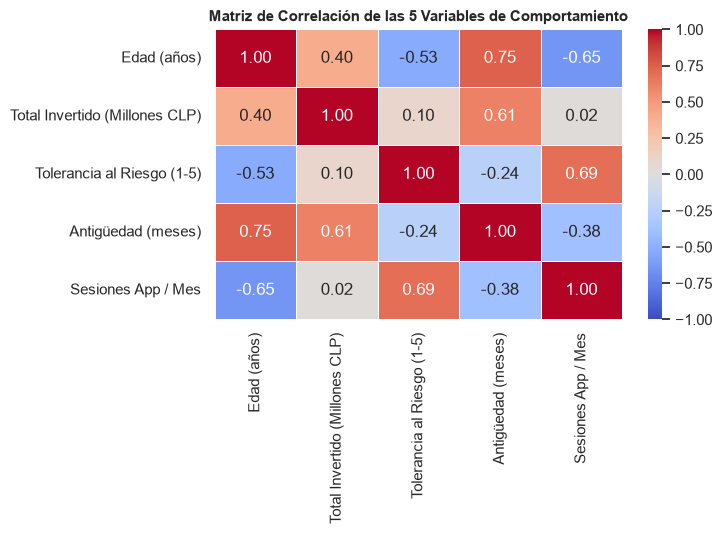

In [13]:
# MATRIZ DE CORRELACIÓN DE LAS 5 VARIABLES DE COMPORTAMIENTO
df_corr = usuarios_copia[variables_obj].rename(columns=nombres_esp)
matriz_corr = df_corr.corr()
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación de las 5 Variables de Comportamiento", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

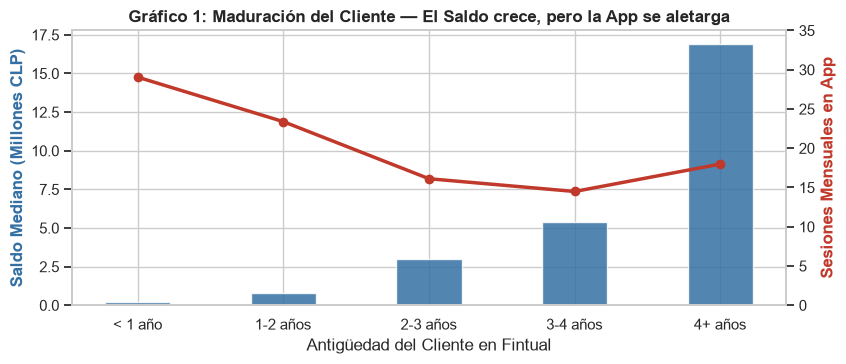

In [14]:
# GRÁFICO 1: Curva de maduración del cliente (Saldo mediano vs. Sesiones mensuales)
usuarios_copia["anios_activo"] = pd.cut(
    usuarios_copia["months_active"],
    bins=[0, 12, 24, 36, 48, 100],
    labels=["< 1 año", "1-2 años", "2-3 años", "3-4 años", "4+ años"]
)
maduracion = usuarios_copia.groupby("anios_activo", observed=False).agg(
    saldo_mediano=("total_invested", lambda x: x.median() / 1_000_000),
    sesiones_prom=("app_sessions_month", "mean")
).reset_index()
fig, ax1 = plt.subplots(figsize=(8.5, 3.8))
# Barras (Eje izquierdo): Saldo mediano en millones de CLP
ax1.bar(maduracion["anios_activo"], maduracion["saldo_mediano"], color="#3470a3", width=0.45, alpha=0.85)
ax1.set_xlabel("Antigüedad del Cliente en Fintual")
ax1.set_ylabel("Saldo Mediano (Millones CLP)", color="#3470a3", fontweight="bold")
# Línea (Eje derecho twinx): Sesiones mensuales promedio
ax2 = ax1.twinx()
ax2.plot(maduracion["anios_activo"], maduracion["sesiones_prom"], color="#c0392b", marker="o", linewidth=2.5)
ax2.set_ylabel("Sesiones Mensuales en App", color="#c0392b", fontweight="bold")
ax2.set_ylim(0, 35)
ax2.grid(False)
plt.title("Gráfico 1: Maduración del Cliente — El Saldo crece, pero la App se aletarga", fontweight="bold")
plt.tight_layout()
plt.show()

Grafico 1: A medida que aumenta la antigüedad del cliente, el saldo mediano crece de forma sostenida (de 0,19 M en el primer año a 16,9 M con más de 4 años), mientras que la frecuencia de uso de la app cae de 29,1 sesiones mensuales en el primer año a 14,5 en el tramo de 3 a 4 años y repunta levemente a 18,0 en el de 4+ años. Es decir, la caída no es estrictamente progresiva. Este comportamiento admite dos hipótesis:
- Mayor confianza en el producto y maduración: El usuario entiende la idea de inversión a largo plazo y confía en la gestión.
- Pérdida de interés por la aplicación: El usuario solamente ingresa cuando quiere hacer algún tipo de transacción.
Ninguna de las dos se puede probar con estos datos; sirven como hipótesis a validar en las entrevistas.

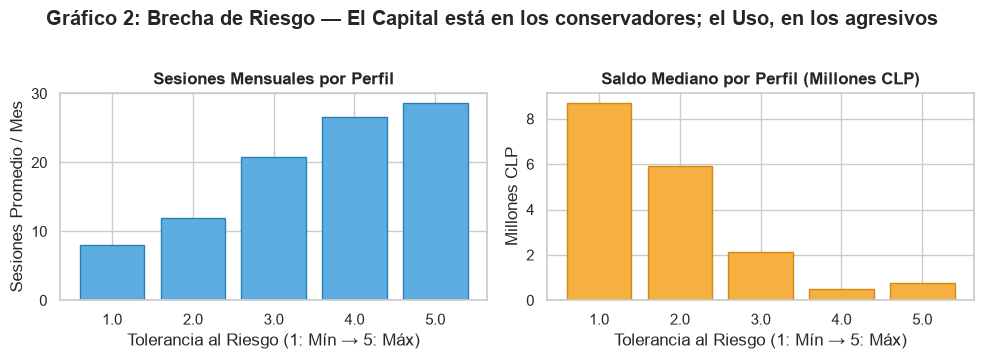

In [15]:
# GRÁFICO 2: Engagement y Saldo por Nivel de Tolerancia al Riesgo
riesgo = usuarios_copia.groupby("risk_tolerance").agg(
    sesiones_prom=("app_sessions_month", "mean"),
    saldo_mediano=("total_invested", lambda x: x.median() / 1_000_000)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

# Panel izquierdo: Sesiones mensuales
ax[0].bar(riesgo["risk_tolerance"].astype(str), riesgo["sesiones_prom"], color="#5dade2", edgecolor="#2980b9")
ax[0].set_title("Sesiones Mensuales por Perfil", fontweight="bold")
ax[0].set_xlabel("Tolerancia al Riesgo (1: Mín → 5: Máx)")
ax[0].set_ylabel("Sesiones Promedio / Mes")

# Panel derecho: Saldo mediano
ax[1].bar(riesgo["risk_tolerance"].astype(str), riesgo["saldo_mediano"], color="#f5b041", edgecolor="#d68910")
ax[1].set_title("Saldo Mediano por Perfil (Millones CLP)", fontweight="bold")
ax[1].set_xlabel("Tolerancia al Riesgo (1: Mín → 5: Máx)")
ax[1].set_ylabel("Millones CLP")

plt.suptitle("Gráfico 2: Brecha de Riesgo — El Capital está en los conservadores; el Uso, en los agresivos", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Grafico 2: Este grafico evidencia una relación inversa entre patrimonio y frecuencia de uso: mientras los usuarios conservadores concentran el grueso del capital en Fintual con una interacción esporádica, los clientes con perfiles arriesgados son los más activos digitalmente en la app, a pesar de mantener saldos considerablemente menores.

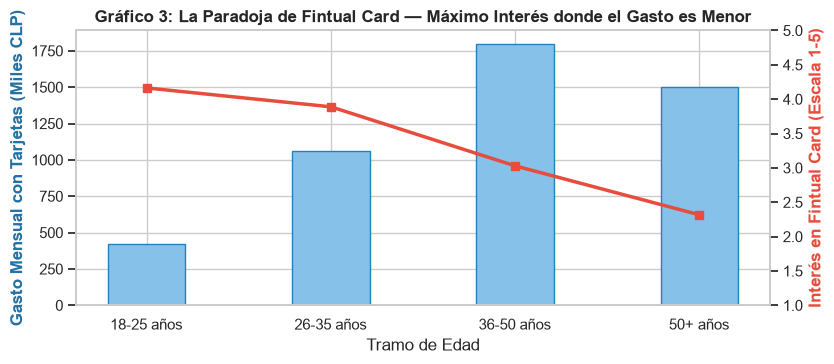

In [16]:
# GRÁFICO 3: Paradoja de Fintual Card (Gasto mensual con tarjetas vs. Interés declarado)
df_completo = usuarios_copia.merge(caracteristicas_copia, on="user_id", how="left")

df_completo["tramo_edad"] = pd.cut(
    df_completo["age"],
    bins=[17, 25, 35, 50, 100],
    labels=["18-25 años", "26-35 años", "36-50 años", "50+ años"]
)

paradoja = df_completo.groupby("tramo_edad", observed=False).agg(
    gasto_k=("gasto_mensual_tarjetas_clp", lambda x: x.mean() / 1_000),
    interes_prom=("interes_fintual_card", "mean")
).reset_index()

fig, ax1 = plt.subplots(figsize=(8.5, 3.8))

# Barras (Eje izquierdo): Gasto mensual con tarjetas en miles de CLP
ax1.bar(paradoja["tramo_edad"], paradoja["gasto_k"], color="#85c1e9", edgecolor="#2980b9", width=0.42)
ax1.set_xlabel("Tramo de Edad")
ax1.set_ylabel("Gasto Mensual con Tarjetas (Miles CLP)", color="#2471a3", fontweight="bold")

# Línea (Eje derecho twinx): Interés promedio en Fintual Card (1 a 5)
ax2 = ax1.twinx()
ax2.plot(paradoja["tramo_edad"], paradoja["interes_prom"], color="#e74c3c", marker="s", linewidth=2.5)
ax2.set_ylabel("Interés en Fintual Card (Escala 1-5)", color="#e74c3c", fontweight="bold")
ax2.set_ylim(1, 5)
ax2.grid(False)

plt.title("Gráfico 3: La Paradoja de Fintual Card — Máximo Interés donde el Gasto es Menor", fontweight="bold")
plt.tight_layout()
plt.show()

Grafico 3: El interés declarado en Fintual Card decrece con la edad: es máximo en el tramo 18-25 años (4,16) y mínimo en el tramo 50+ años (2,32). El gasto mensual con tarjetas, en cambio, es máximo en el tramo 36-50 años (CLP 1.800 mil), y en el tramo más joven es de solo CLP 420 mil. Es el dilema central: quienes más quieren la tarjeta son quienes menos gastan, y quienes más gastan muestran un interés intermedio. Una estrategia masiva en cualquiera de los extremos sería ineficiente, lo que justifica buscar un segmento intermedio que combine intención y capacidad de gasto.

In [17]:
# 1. Matriz estandarizada en escala original (para comparar en 2.3)
scaler_orig = StandardScaler()
X_scaled_orig = scaler_orig.fit_transform(usuarios_copia[variables_obj])

# 2. Matriz estandarizada con transformación logarítmica (log1p) en total_invested
usuarios_log = usuarios_copia[variables_obj].copy()
usuarios_log["total_invested"] = np.log1p(usuarios_log["total_invested"])

scaler_log = StandardScaler()
X_scaled_log = scaler_log.fit_transform(usuarios_log)

## Parte 2.2: Clustering jerárquico

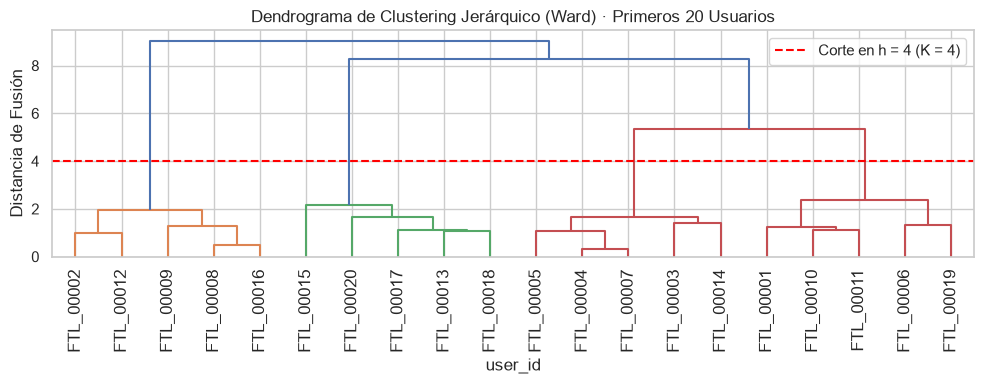

Últimas distancias de fusión: [1.96 2.15 2.36 5.36 8.27 9.02]


In [18]:
# Construccion del dendograma

# 1. Tomamos los primeros 20 usuarios estandarizados
X_20 = X_scaled_log[:20]
user_ids_20 = usuarios_copia['user_id'].iloc[:20].tolist()

# 2. Matriz de enlace Ward y dendrograma
L = linkage(X_20, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(L, labels=user_ids_20, leaf_rotation=90)
plt.axhline(y=4, color="red", linestyle="--", label="Corte en h = 4 (K = 4)")

plt.title("Dendrograma de Clustering Jerárquico (Ward) · Primeros 20 Usuarios")
plt.ylabel("Distancia de Fusión")
plt.xlabel("user_id")
plt.legend()
plt.tight_layout()
plt.show()

print("Últimas distancias de fusión:", L[-6:, 2].round(2))

La eleccion del corte en h=4 se justifica en que allí se produce el mayor salto relativo entre las distancias de fusion (de 2,36 a 5,36). un salto grande significa que estariamos forzando uniones entre grupos muy diferentes entre ellos. 

Viendo el corte en h=4, podemos obersvar que se formaron 4 grupos.

In [19]:
# Asignación de los 20 primeros usuarios a sus 4 clusters (corte en h = 4)
df_20 = usuarios_copia.iloc[:20][["user_id"] + variables_obj].copy()
df_20["cluster_jerarquico"] = fcluster(L, t=4, criterion="distance")

print("Promedio por cluster jerárquico (y cantidad de usuarios n)")
display(df_20.groupby("cluster_jerarquico")[variables_obj].mean().round(1).assign(n=df_20["cluster_jerarquico"].value_counts()))

Promedio por cluster jerárquico (y cantidad de usuarios n)


,age,total_invested,risk_tolerance,months_active,app_sessions_month,n
cluster_jerarquico,,,,,,
1,23.20,"273,900.00",4.00,10.60,26.40,5
2,40.00,"48,069,880.00",4.40,60.00,34.00,5
3,33.00,"5,046,460.00",2.80,31.20,17.60,5
4,51.00,"8,995,600.00",1.40,43.60,9.60,5


## Parte 2.3: K-Means 

In [20]:
# 1. Evaluar K entre 2 y 8 sobre la matriz estandarizada con log1p (X_scaled_log)
resultados_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X_scaled_log)
    sil = silhouette_score(X_scaled_log, km.labels_)
    resultados_k.append((k, km.inertia_, sil))

resumen_kmeans = pd.DataFrame(resultados_k, columns=["K", "inercia", "silhouette"])

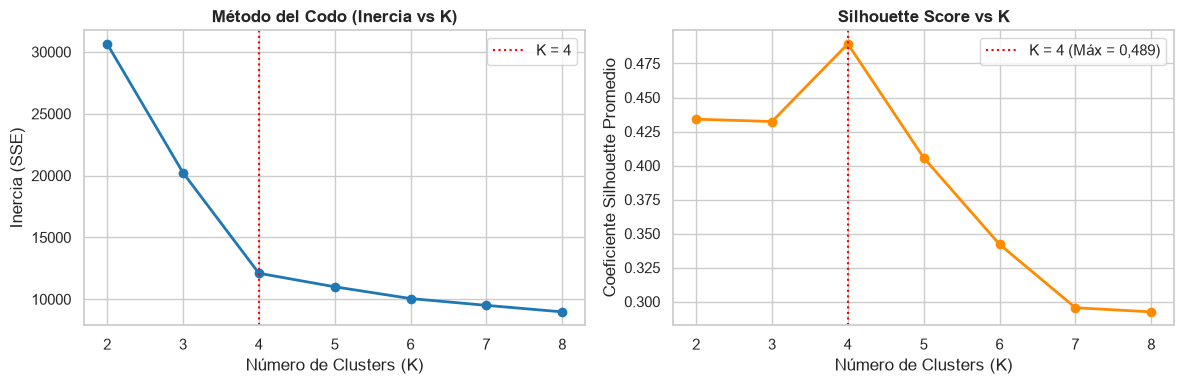

,K,inercia,silhouette
0,2,"30,651.02",0.43
1,3,"20,233.89",0.43
2,4,"12,102.81",0.49
3,5,"11,005.14",0.41
4,6,"10,054.24",0.34
5,7,"9,504.09",0.30
6,8,"8,977.18",0.29


In [21]:
# 2. Gráficos de Codo y Silhouette lado a lado
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(resumen_kmeans["K"], resumen_kmeans["inercia"], "o-", color="tab:blue", linewidth=2)
ax[0].axvline(4, color="red", linestyle=":", label="K = 4")
ax[0].set_title("Método del Codo (Inercia vs K)", fontweight="bold")
ax[0].set_xlabel("Número de Clusters (K)")
ax[0].set_ylabel("Inercia (SSE)")
ax[0].legend()
ax[1].plot(resumen_kmeans["K"], resumen_kmeans["silhouette"], "o-", color="darkorange", linewidth=2)
ax[1].axvline(4, color="red", linestyle=":", label="K = 4 (Máx = 0,489)")
ax[1].set_title("Silhouette Score vs K", fontweight="bold")
ax[1].set_xlabel("Número de Clusters (K)")
ax[1].set_ylabel("Coeficiente Silhouette Promedio")
ax[1].legend()
plt.tight_layout()
plt.show()
display(resumen_kmeans.round(3))

Evaluando entre 2 y 8 grupos (K entre 2 y 8), la mejor cantidad de clústeres (grupos) es 4, ya que alcanza el maximo coeficiente de silueta (0,49), se puede observar en el grafico "Silhouette Score vs K". En grafico "Método del codo (Inercia vs k)" podemos ver como la curva cambia drasticamente su pendiente al pasar de 3 a 4. Si hacemos un quinto grupo no encontrariamos frandes diferencia, por lo que hay probabilidades altas de mezclar grupos de personas muy distintas en el mismop clúster.

In [22]:
# 1. Ejecutar K=3 y K=4 
kmeans3 = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42).fit(X_scaled_log)
kmeans4 = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42).fit(X_scaled_log)

usuarios_copia["kmeans3"] = kmeans3.labels_
usuarios_copia["kmeans4"] = kmeans4.labels_

# 2. Función para reportar centroides des-estandarizados (CLP) + mediana y media real de inversión
def tabla_centroides(km, col_cluster):
    # Invertimos el StandardScaler y luego el log1p (expm1 = media geométrica en CLP)
    centroides = pd.DataFrame(scaler_log.inverse_transform(km.cluster_centers_), columns=variables_obj)
    centroides["total_invested"] = np.expm1(centroides["total_invested"])
        # Agregamos mediana y media aritmética real en CLP y cantidad de clientes (n)
    centroides["inversión_mediana_real"] = usuarios_copia.groupby(col_cluster)["total_invested"].median().values
    centroides["inversión_media_real"] = usuarios_copia.groupby(col_cluster)["total_invested"].mean().values
    centroides["n_usuarios"] = np.bincount(km.labels_)
    return centroides.round(1)

silueta_k3 = silhouette_score(X_scaled_log, usuarios_copia["kmeans3"])
silueta_k4 = silhouette_score(X_scaled_log, usuarios_copia["kmeans4"])
print(f"K = 3 · Inercia: {kmeans3.inertia_:,.0f} · Silhouette: {silueta_k3:.3f}")
display(tabla_centroides(kmeans3, "kmeans3"))
print(f"\n K = 4 · Inercia: {kmeans4.inertia_:,.0f} · Silhouette: {silueta_k4:.3f}")
display(tabla_centroides(kmeans4, "kmeans4"))


K = 3 · Inercia: 20,234 · Silhouette: 0.432


,age,total_invested,risk_tolerance,months_active,app_sessions_month,inversión_mediana_real,inversión_media_real,n_usuarios
0,35.10,"6,000,320.80",3.50,41.10,21.00,"4,203,700.00","12,904,909.80",5357
1,23.10,"184,819.60",3.90,9.20,29.50,"181,300.00","249,368.70",4049
2,47.40,"8,644,416.90",1.70,51.40,7.60,"8,882,150.00","10,486,186.20",2594



 K = 4 · Inercia: 12,103 · Silhouette: 0.489


,age,total_invested,risk_tolerance,months_active,app_sessions_month,inversión_mediana_real,inversión_media_real,n_usuarios
0,39.20,"28,125,875.00",4.40,64.00,28.60,"27,699,000.00","32,176,411.90",1761
1,23.10,"183,439.00",3.90,9.10,29.50,"180,700.00","246,126.70",4027
2,47.90,"8,977,646.80",1.70,52.30,7.40,"9,112,700.00","10,729,297.80",2483
3,33.10,"2,816,240.70",3.00,29.90,17.10,"2,774,100.00","3,499,008.60",3729


In [23]:
# 1. ¿Qué segmento aparece al pasar de K=3 a K=4? 
print("Tránsito de usuarios (DE k=3 A K=4)")
display(pd.crosstab(usuarios_copia["kmeans3"], usuarios_copia["kmeans4"], rownames=["Cluster Kmeans=3"], colnames=["Cluster Kmeans=4"]))

# 2. Evaluar si cambian las conclusiones SIN transformación logarítmica (usando X_scaled_orig)
resultados_sin_log = []
for k in range(2, 9):
    km_orig = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X_scaled_orig)
    resultados_sin_log.append((k, km_orig.inertia_, silhouette_score(X_scaled_orig, km_orig.labels_)))

df_sin_log = pd.DataFrame(resultados_sin_log, columns=["K", "inercia_sin_log", "silhouette_sin_log"])
comparacion_log = resumen_kmeans.rename(columns={"inercia": "inercia_con_log", "silhouette": "silhouette_con_log"}).merge(df_sin_log, on="K")

print("Comparación de Inercia y Silhouette CON log vs. SIN log")
display(comparacion_log.round(3))

# 3. Índice de coincidencia (Adjusted Rand Index - ARI) entre clusters con y sin log
km3_sin_log = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42).fit(X_scaled_orig)
km4_sin_log = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42).fit(X_scaled_orig)

ari_k3 = adjusted_rand_score(kmeans3.labels_, km3_sin_log.labels_)
ari_k4 = adjusted_rand_score(kmeans4.labels_, km4_sin_log.labels_)
print(f"Coincidencia de grupos (ARI) CON vs SIN log -> En K=3: {ari_k3:.3f} | En K=4: {ari_k4:.3f}")

Tránsito de usuarios (DE k=3 A K=4)


Cluster Kmeans=4,0,1,2,3
Cluster Kmeans=3,,,,
0,1759,0,2,3596
1,0,4027,0,22
2,2,0,2481,111


Comparación de Inercia y Silhouette CON log vs. SIN log


,K,inercia_con_log,silhouette_con_log,inercia_sin_log,silhouette_sin_log
0,2,"30,651.02",0.43,"37,060.93",0.38
1,3,"20,233.89",0.43,"23,245.00",0.45
2,4,"12,102.81",0.49,"15,661.61",0.45
3,5,"11,005.14",0.41,"13,383.16",0.46
4,6,"10,054.24",0.34,"12,300.56",0.39
5,7,"9,504.09",0.30,"11,177.83",0.37
6,8,"8,977.18",0.29,"10,230.01",0.33


Coincidencia de grupos (ARI) CON vs SIN log -> En K=3: 0.358 | En K=4: 0.981


Como se muestra en la tabla de "Tránsito de usuarios (DE k=3 A K=4)" cuando usamos 3 grupos, el primero concentra un total de 5355 usuarios, manteniendo unidos a perfiles que en K=4 se dividen (3596 en un grupo y 1759 en otro). En cambio los grupos 1 y 2 practicamente no presentan cambios. Por lo tanto no es recomendable utilizar 3 grupos ya que se estaria forzando la union entre personas con caracteristicas muy distitnas entre si.

Por otro lado, al comparar la segmentacion con y sin transformación logatimica en "total_invested", podemos observar que sin logaritmo no existe una distincion clara sobre la cantidad ideal de clústertes a escoger, ya que K=3, K=4 Y K=5 apendas tiene diferencias en sus coeficiente de silueta. Además, la metrica ARI demuestra que en K=3, la coincidencia entre usar y no usar logaritmo es de un 35,8%, mientras que en K=4, la coincidencia etre usar y no usar logaritmo es de un 98.1%, asi se demuestra que es mejor usar K=4.

## Parte 2.4: Perfilamiento accionable de segmentos 

In [24]:
# 1. Unimos la base de comportamiento (que tiene la columna 'kmeans4') con la demografía limpia
df_completo = usuarios_copia.merge(caracteristicas_copia, on="user_id", how="left")

# 2. Columna auxiliar (0 o 100) para calcular el % de clientes con alto interés (notas 4 o 5)
df_completo["alto_interes"] = np.where(
    df_completo["interes_fintual_card"].isna(), np.nan,
    (df_completo["interes_fintual_card"] >= 4) * 100
)

# 3. Caracterización cuantitativa agrupando por el número de cluster (0, 1, 2, 3)
resumen_clusters = df_completo.groupby("kmeans4").agg(
    clientes=("user_id", "count"),
    edad_prom=("age", "mean"),
    meses_activo=("months_active", "mean"),
    sesiones_app=("app_sessions_month", "mean"),
    riesgo_prom=("risk_tolerance", "mean"),
    saldo_mediano_clp=("total_invested", "median"),
    aum_total=("total_invested", "sum"),
    gasto_tarjetas_prom=("gasto_mensual_tarjetas_clp", "mean"),
    gasto_tarjetas_total=("gasto_mensual_tarjetas_clp", "sum"),
    interes_card_prom=("interes_fintual_card", "mean"),
    interes_Fincard=("alto_interes", "mean")
)

# 4. Agregamos cuánto pesa cada cluster en % de Clientes, % de AUM y % de Gasto con tarjetas
resumen_clusters["% clientes"] = resumen_clusters["clientes"] / len(df_completo) * 100
resumen_clusters["% AUM Fintual"] = resumen_clusters["aum_total"] / df_completo["total_invested"].sum() * 100
resumen_clusters["% Gasto Tarjetas"] = resumen_clusters["gasto_tarjetas_total"] / df_completo["gasto_mensual_tarjetas_clp"].sum() * 100

columnas_orden = [
    "clientes", "% clientes", "% AUM Fintual", "saldo_mediano_clp",
    "gasto_tarjetas_prom", "% Gasto Tarjetas", "edad_prom", "meses_activo",
    "sesiones_app", "riesgo_prom", "interes_card_prom", "interes_Fincard"
]
display(resumen_clusters[columnas_orden].round(2))

,clientes,% clientes,% AUM Fintual,saldo_mediano_clp,gasto_tarjetas_prom,% Gasto Tarjetas,edad_prom,meses_activo,sesiones_app,riesgo_prom,interes_card_prom,interes_Fincard
kmeans4,,,,,,,,,,,,
0,1761,14.68,58.21,"27,699,000.00","2,664,222.60",33.83,39.23,64.00,28.63,4.37,3.27,41.04
1,4027,33.56,1.02,"180,700.00","408,439.28",11.86,23.10,9.13,29.54,3.93,4.18,82.78
2,2483,20.69,27.37,"9,112,700.00","1,497,828.43",26.82,47.88,52.31,7.42,1.66,2.35,8.77
3,3729,31.08,13.40,"2,774,100.00","1,022,293.91",27.49,33.09,29.85,17.14,2.98,3.90,70.98


In [25]:
# Distribución porcentual de variables categóricas por cluster (0, 1, 2, 3)
variables_perfil = [
    "tiene_tarjeta_credito",
    "billetera_digital_principal",
    "banco_principal",
    "ocupacion",
    "tramo_ingreso"
]

for col in variables_perfil:
    print(f"\nDistribución de '{col}' por cluster (%)")
    tabla_pct = pd.crosstab(df_completo["kmeans4"], df_completo[col], normalize="index") * 100
    display(tabla_pct.round(1))

# Región: mostramos las 3 regiones principales + 'Sin dato'
print("\nPrincipales regiones por cluster (%)")
tabla_reg = pd.crosstab(df_completo["kmeans4"], df_completo["region"], normalize="index") * 100
display(tabla_reg[["Metropolitana de Santiago", "Valparaíso", "Biobío", "Sin dato"]].round(1))


Distribución de 'tiene_tarjeta_credito' por cluster (%)


tiene_tarjeta_credito,No,Sí
kmeans4,,
0,3.10,96.90
1,76.60,23.40
2,6.80,93.20
3,18.90,81.10



Distribución de 'billetera_digital_principal' por cluster (%)


billetera_digital_principal,MACH,Mercado Pago,Ninguna,Otra,Tenpo
kmeans4,,,,,
0,10.80,24.60,51.90,4.90,7.80
1,13.50,45.80,9.70,3.90,27.10
2,5.20,11.80,76.10,3.80,3.10
3,14.90,32.90,33.50,4.80,14.00



Distribución de 'banco_principal' por cluster (%)


banco_principal,BCI,BICE,Banco Falabella,Banco de Chile,BancoEstado,Itaú,Mercado Pago,Otro,Santander,Scotiabank,Security,Tenpo
kmeans4,,,,,,,,,,,,
0,13.70,11.00,1.90,31.10,2.50,4.00,0.90,0.00,21.20,3.90,9.90,0.00
1,5.20,0.00,4.70,6.00,36.00,1.10,19.30,1.70,6.20,2.40,0.00,17.40
2,16.40,2.30,6.20,27.70,12.90,4.80,0.00,0.00,20.70,6.40,2.70,0.00
3,16.70,2.20,5.90,23.10,12.20,4.80,2.10,1.30,18.20,6.90,3.10,3.60


... (2 outputs left out)


Distribución de 'tramo_ingreso' por cluster (%)


tramo_ingreso,$1.200.001 - $2.500.000,$2.500.001 - $4.500.000,$600.000 - $1.200.000,Menos de $600.000,Más de $4.500.000,No declara
kmeans4,,,,,,
0,10.70,32.00,2.10,0.00,46.70,8.50
1,12.90,2.50,34.00,42.20,0.60,7.90
2,32.70,30.10,11.20,2.70,15.70,7.70
3,41.40,21.20,20.50,3.50,4.50,8.90



Principales regiones por cluster (%)


region,Metropolitana de Santiago,Valparaíso,Biobío,Sin dato
kmeans4,,,,
0,57.40,8.90,7.70,1.10
1,56.80,9.80,7.30,0.80
2,55.90,10.40,6.50,1.40
3,57.50,10.70,6.90,0.80


In [26]:
# Habiendo analizado el perfil de cada grupo (0 a 3), asignamos los nombres de marketing
nombres_segmentos = {
    0: "Inversionistas Wealth",
    1: "Nativos Digitales Emergentes",
    2: "Conservadores Tradicionales",
    3: "Profesionales en Construcción"
}
df_completo["segmento"] = df_completo["kmeans4"].map(nombres_segmentos)

display(df_completo.head(10))

,user_id,age,total_invested,risk_tolerance,months_active,app_sessions_month,anios_activo,kmeans3,kmeans4,region,genero,tramo_ingreso,ocupacion,banco_principal,tiene_tarjeta_credito,n_tarjetas_credito,billetera_digital_principal,gasto_mensual_tarjetas_clp,interes_fintual_card,alto_interes,segmento
0,FTL_00001,45.00,18921200,2.00,37,11.00,3-4 años,2,2,Los Lagos,Masculino,Más de $4.500.000,Dependiente,BCI,Sí,1,Otra,741000,1.00,0.00,Conservadores Tradicionales
1,FTL_00002,24.00,462700,3.00,9,19.00,< 1 año,1,1,Metropolitana de Santiago,Masculino,Menos de $600.000,Dependiente,Mercado Pago,No,0,Mercado Pago,454000,NaN,NaN,Nativos Digitales Emergentes
2,FTL_00003,28.00,4516300,2.00,29,16.00,2-3 años,0,3,Araucanía,Femenino,$1.200.001 - $2.500.000,Dependiente,Banco de Chile,Sí,2,Mercado Pago,1214000,NaN,NaN,Profesionales en Construcción
3,FTL_00004,33.00,4236500,3.00,32,21.00,2-3 años,0,3,Metropolitana de Santiago,Femenino,$2.500.001 - $4.500.000,Dependiente,Banco de Chile,Sí,1,Ninguna,704000,NaN,NaN,Profesionales en Construcción
4,FTL_00005,35.00,11220200,3.00,46,16.00,3-4 años,0,3,Araucanía,Masculino,$1.200.001 - $2.500.000,Dependiente,BCI,Sí,2,Ninguna,866000,5.00,100.00,Profesionales en Construcción
5,FTL_00006,57.00,5528400,2.00,49,2.00,4+ años,2,2,Metropolitana de Santiago,Masculino,$1.200.001 - $2.500.000,Dependiente,Banco de Chile,Sí,1,Ninguna,3203000,NaN,NaN,Conservadores Tradicionales
6,FTL_00007,34.00,2993300,3.00,37,21.00,3-4 años,0,3,O'Higgins,Masculino,$600.000 - $1.200.000,Independiente,BancoEstado,Sí,2,Ninguna,1192000,4.00,100.00,Profesionales en Construcción
7,FTL_00008,24.00,84100,4.00,9,31.00,< 1 año,1,1,Metropolitana de Santiago,Masculino,Menos de $600.000,Dependiente,Mercado Pago,Sí,1,Mercado Pago,330000,3.00,0.00,Nativos Digitales Emergentes
8,FTL_00009,21.00,390300,5.00,12,29.00,< 1 año,1,1,Araucanía,Femenino,Menos de $600.000,Dependiente,Tenpo,No,0,Ninguna,476000,4.00,100.00,Nativos Digitales Emergentes
9,FTL_00010,43.00,4185800,1.00,32,10.00,2-3 años,2,2,Valparaíso,Masculino,No declara,Dependiente,Security,Sí,1,Ninguna,1373000,4.00,100.00,Conservadores Tradicionales


### Buyer Personas por Segmento

#### 1. Cluster 0 · Inversionistas Wealth ("El inversionista consolidado")
| Rasgo | Evidencia (Datos y Trabajo de Campo) |
|---|---|
| **Nombre del segmento** | Inversionistas Wealth (Cluster 0) |
| **Quién es (edad, ocupación, ingreso, región)** | **39,2 años** en promedio; **45,8%** Dependiente y **32,5%** Empresario; ingreso modal **> CLP 4.500.000** (**46,7%** del grupo); **57,4%** vive en la Región Metropolitana. |
| **Cómo se comporta en Fintual (app, riesgo, antigüedad)** | **28,6 sesiones/mes** en la app; perfil agresivo con tolerancia al riesgo de **4,4 / 5**; clientes más antiguos con **64,0 meses** (más de 5 años). |
| **Cuánto vale (% clientes, saldo, % AUM)** | **1.761 usuarios** (**14,7%** de la base), pero concentran el **58,2% del AUM total** de Fintual, con un saldo mediano de **CLP 27,7 millones** (promedio CLP 32,2M). |
| **Cómo paga hoy (TC, banco, billetera, gasto)** | **96,9%** tiene tarjeta de crédito (**2,2 tarjetas** en promedio); banco principal: **Banco de Chile (31,1%)** y **Santander (21,2%)**; billetera: **Ninguna (51,9%)** o **Mercado Pago (24,6%)**; gasto mensual en tarjetas de **CLP 2,66 millones** (**33,8%** del gasto total). |
| **Qué tan interesado está en Fintual Card** | Interés moderado: promedio de **3,27 / 5**; el **41,0%** de quienes respondieron declara interés alto (notas 4 o 5, equivalente a **513 clientes**). |
| **Cita de entrevista** | *"[Pegar aquí cita de tus entrevistas de perfil de alto ingreso/inversionista]"* |

---

#### 2. Cluster 1 · Nativos Digitales Emergentes ("El joven que recién parte")
| Rasgo | Evidencia (Datos y Trabajo de Campo) |
|---|---|
| **Nombre del segmento** | Nativos Digitales Emergentes (Cluster 1) |
| **Quién es (edad, ocupación, ingreso, región)** | **23,1 años** en promedio; **49,1%** Dependiente y **41,4%** Estudiante; ingreso modal **< CLP 600.000** (**42,2%** del grupo); **56,8%** en la Región Metropolitana. |
| **Cómo se comporta en Fintual (app, riesgo, antigüedad)** | Muy activos en la app (**29,5 sesiones/mes**); tolerancia al riesgo alta (**3,9 / 5**); clientes nuevos con **9,1 meses** de antigüedad promedio. |
| **Cuánto vale (% clientes, saldo, % AUM)** | Es el grupo más numeroso con **4.027 usuarios** (**33,6%** de la base), pero representa solo el **1,0% del AUM total**, con un saldo mediano de **CLP 183.700**. |
| **Cómo paga hoy (TC, banco, billetera, gasto)** | Solo el **23,4%** tiene tarjeta de crédito (**0,3 tarjetas** prom.); cuenta principal en **BancoEstado (36,0%)**, **Mercado Pago (19,3%)** y **Tenpo (17,4%)**; billetera: **Mercado Pago (45,8%)** y **Tenpo (27,1%)**; gasto mensual de **CLP 410 mil** (**11,9%** del gasto total). |
| **Qué tan interesado está en Fintual Card** | **Máximo interés de la base:** promedio de **4,18 / 5**; el **82,8%** declara interés alto (notas 4 o 5, equivalente a **2.418 clientes**). |
| **Cita de entrevista** | *"[Pegar aquí cita de tus entrevistas de perfil joven / usuario de prepago]"* |

---

#### 3. Cluster 2 · Conservadores Tradicionales ("El ahorrista clásico")
| Rasgo | Evidencia (Datos y Trabajo de Campo) |
|---|---|
| **Nombre del segmento** | Conservadores Tradicionales (Cluster 2) |
| **Quién es (edad, ocupación, ingreso, región)** | **47,9 años** en promedio; **73,5%** Dependiente y **16,9%** Independiente; ingreso modal **CLP 1,2M – 2,5M** (**32,7%**); **55,9%** en la Región Metropolitana. |
| **Cómo se comporta en Fintual (app, riesgo, antigüedad)** | Uso muy pasivo de la app (**7,4 sesiones/mes**); baja tolerancia al riesgo (**1,7 / 5**); alta antigüedad con **52,3 meses** promedio. |
| **Cuánto vale (% clientes, saldo, % AUM)** | **2.483 usuarios** (**20,7%** de la base) que concentran el **27,4% del AUM total** de Fintual, con un saldo mediano de **CLP 9,11 millones** (promedio CLP 10,8M). |
| **Cómo paga hoy (TC, banco, billetera, gasto)** | **93,2%** tiene tarjeta de crédito (**1,7 tarjetas** prom.); banco principal: **Banco de Chile (27,7%)** y **Santander (20,7%)**; el **76,1% no usa ninguna billetera digital**; gasto mensual con tarjetas de **CLP 1,50 millones** (**26,8%** del gasto total). |
| **Qué tan interesado está en Fintual Card** | **Mínimo interés de la base:** promedio de **2,35 / 5**; apenas el **8,8%** declara interés alto (notas 4 o 5, solo **156 clientes**). |
| **Cita de entrevista** | *"[Pegar aquí cita que refleje apego al banco tradicional o desinterés por tarjetas prepago]"* |

---

#### 4. Cluster 3 · Profesionales en Construcción ("El profesional en crecimiento")
| Rasgo | Evidencia (Datos y Trabajo de Campo) |
|---|---|
| **Nombre del segmento** | Profesionales en Construcción  |
| **Quién es (edad, ocupación, ingreso, región)** | 33,1 años en promedio; 83,1%** Dependiente y 12,7% Independiente; ingreso modal CLP 1,2M – 2,5M (41,4%); 57,5% en la Región Metropolitana. |
| **Cómo se comporta en Fintual (app, riesgo, antigüedad) | Uso regular de la app (**17,1 sesiones/mes**); perfil de riesgo moderado (**3,0 / 5**); antigüedad consolidada de **29,9 meses** (~2,5 años). |
| **Cuánto vale (% clientes, saldo, % AUM)** | **3.729 usuarios** (**31,1%** de la base) con el **13,4% del AUM total** de Fintual y un saldo mediano de **CLP 2,77 millones** (promedio CLP 3,50M). |
| **Cómo paga hoy (TC, banco, billetera, gasto)** | **81,1%** tiene tarjeta de crédito (**1,3 tarjetas** prom.); banco principal: **Banco de Chile (23,1%)**, **Santander (18,2%)** y **BCI (16,7%)**; billetera dividida entre **Ninguna (33,5%)**, **Mercado Pago (32,9%)** y **Tenpo (17,2%)**; gasto mensual de **CLP 1,02 millones** (**27,5%** del gasto total). |
| **Qué tan interesado está en Fintual Card** | **Alto interés:** promedio de **3,90 / 5**; el **71,0%** declara interés alto (notas 4 o 5, equivalente a **1.886 clientes**). |
| **Cita de entrevista** | *"[Pegar aquí cita de tus entrevistas de perfil profesional 28-40 años]"* |

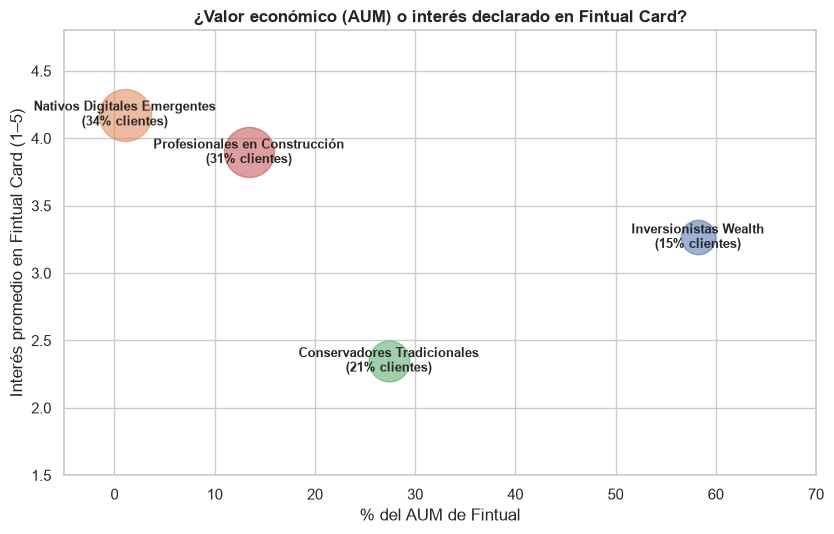

In [27]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for cluster_id, r in resumen_clusters.iterrows():
    nombre = nombres_segmentos[cluster_id]
    ax.scatter(r["% AUM Fintual"], r["interes_card_prom"], s=r["clientes"] * 0.35, alpha=.55)
    ax.annotate(f"{nombre}\n({r['% clientes']:.0f}% clientes)", (r["% AUM Fintual"], r["interes_card_prom"]), ha="center", va="center", fontsize=9, fontweight="bold")

ax.set_xlabel("% del AUM de Fintual")
ax.set_ylabel("Interés promedio en Fintual Card (1–5)")
ax.set_title("¿Valor económico (AUM) o interés declarado en Fintual Card?", fontweight="bold")
ax.set_xlim(-5, 70)
ax.set_ylim(1.5, 4.8)
plt.tight_layout()
plt.show()

Los inversionistas Wealth representan la mayor parte de los activos de fintual, sin embargo el interes que tienen por la Fintual Card es menor en comparción a los nativos digitales emergente y los profesionales en construcción. 

Los nativos emergentes y los profesionales en contrucción son los dos grupos mas interesados la tarjeta.  Los primeros aportan únicamente el 1,2 % de los activos de Fintual, mientras que los profesionales en construcción representan 13,40 %.

Por ultimo, los conservadores Tradicionales representa el segundo grupo más imporatante en términos de activos para Fintual, aunque su inetere por la tarjeta bajo.

En consecuencia, los "Profesionales en Construcción" resultan el segmento más atractivo para fintual, debido a su alto interes por la tarjeta y su potencial de crecimiento en activos. Los inversionistas wealth ya estan consolidados con otros bancos que pueden ofrecerles mejores beneficios, en cambio, si Fintual logra captar a estos profesionales, podra crecer con ellos su patrimonio. Como target secundario, seria captar a los nativos digitales, a pesar de que representan un porcentaje muy bajo de los activos de fintual, son los que más interes presentan por la tarjeta y el grupo con mayor chance de adoptarla porque presentan bancos menos tradicionales y más fintech.

# Parte 3

## Parte 3.1: Validación previa 

In [28]:
# Configuracion tecnica obligatoria: Las librerias estan al inicio
perception_columns = list(fintual_percepcion.columns[2:])

# Promedio por marca (las celdas NS/NR quedan fuera del promedio)
perception_by_brand = fintual_percepcion.groupby('brand')[perception_columns].mean()
data_scaled = StandardScaler().fit_transform(perception_by_brand)

pca = PCA(n_components=3, random_state=42)
mds = MDS(n_components=2, metric='euclidean', metric_mds=True,
          init='classical_mds', normalized_stress=True,
          random_state=42, max_iter=300)

In [29]:
# 1. Duplicados
duplicados_perc = fintual_percepcion.duplicated().sum()

# 2. Rangos válidos (escala Likert 1 a 7)
fuera_de_rango = {
    col: fintual_percepcion[col][~fintual_percepcion[col].between(1, 7) & fintual_percepcion[col].notna()].count()
    for col in perception_columns
}

# 3. Filas completamente vacías
filas_vacias = fintual_percepcion[perception_columns].isna().all(axis=1).sum()

print(f"Filas duplicadas: {duplicados_perc}")
print(f"Filas completamente vacías: {filas_vacias}")
print(f"Valores fuera de rango [1, 7]: {sum(fuera_de_rango.values())}")
print("-> Conclusión: La base está limpia a nivel de registro. Los valores NaN corresponden estrictamente a 'No Sabe / No Responde' (NS/NR).")


Filas duplicadas: 0
Filas completamente vacías: 0
Valores fuera de rango [1, 7]: 0
-> Conclusión: La base está limpia a nivel de registro. Los valores NaN corresponden estrictamente a 'No Sabe / No Responde' (NS/NR).


In [30]:
# % de celdas vacías sobre el total de respuestas posibles (3.000 usuarios × 10 atributos)
nsnr_celdas = (fintual_percepcion.set_index('brand')[perception_columns].isna().groupby('brand').mean().mean(axis=1) * 100).round(2)

# % de usuarios que omitieron al menos 1 atributo
nsnr_usuarios = ((fintual_percepcion.set_index('brand')[perception_columns].isna().sum(axis=1) > 0).groupby('brand').mean() * 100).round(2)

df_nsnr = pd.DataFrame({
    "% Celdas NS/NR": nsnr_celdas,
    "% Usuarios con >=1 NS/NR": nsnr_usuarios
}).sort_values(by="% Celdas NS/NR", ascending=False)

print("TASA DE NS/NR POR MARCA")
display(df_nsnr)

# 2. Cruce de % NS/NR por Marca y Segmento (Parte II)
perc_seg = fintual_percepcion.merge(df_completo[["user_id", "segmento"]], on="user_id")
perc_seg["pct_nsnr"] = perc_seg[perception_columns].isna().mean(axis=1) * 100

tabla_nsnr_seg = perc_seg.pivot_table(
    index="brand", 
    columns="segmento", 
    values="pct_nsnr", 
    aggfunc="mean"
).round(2).loc[df_nsnr.index]

print("\n % CELDAS NS/NR POR MARCA Y SEGMENTO")
display(tabla_nsnr_seg)

TASA DE NS/NR POR MARCA


,% Celdas NS/NR,% Usuarios con >=1 NS/NR
brand,,
Racional,10.36,66.70
MACH,6.60,49.00
Tenpo,5.40,43.07
Banco Falabella,4.55,37.27
Mercado Pago,3.35,29.33
Banco de Chile,3.31,29.13
Fintual,2.41,21.23



 % CELDAS NS/NR POR MARCA Y SEGMENTO


segmento,Conservadores Tradicionales,Inversionistas Wealth,Nativos Digitales Emergentes,Profesionales en Construcción
brand,,,,
Racional,9.86,10.16,10.52,10.61
MACH,6.37,6.83,6.42,6.84
Tenpo,5.67,5.28,5.27,5.41
Banco Falabella,5.06,4.24,4.44,4.47
Mercado Pago,3.11,3.05,3.48,3.52
Banco de Chile,3.39,3.28,3.29,3.30
Fintual,2.58,2.36,2.34,2.39


Como la encuesta se les hizo a los clientes de fintual, es comprensible que sea la marca con mayor reconocimiento entre todos los grupos. Lo importante a destacar son las marcas cercanas a %NSNR que son mercado pago y banco de chile.

Racional es la marca con menor concomiento dentro de los encuestasdos.

In [31]:
# Verificación de diferencias estadísticamente significativas entre marcas
filas_pruebas = []

for a in perception_columns:
    # Grupos por marca omitiendo NaNs por atributo (pairwise deletion)
    grupos = [g[a].dropna() for _, g in fintual_percepcion.groupby('brand')]
    H, pk = stats.kruskal(*grupos)
    F, pa = stats.f_oneway(*grupos)
    filas_pruebas.append({
        "Atributo": a,
        "H (Kruskal)": f"{H:,.1f}",
        "p Kruskal": f"{pk:.2e}" if pk < 0.001 else f"{pk:.4f}",
        "F (ANOVA)": f"{F:,.1f}",
        "p ANOVA": f"{pa:.2e}" if pa < 0.001 else f"{pa:.4f}",
        "¿Discrimina? (p < 0.05)": "Sí" if (pk < 0.05 and pa < 0.05) else "No"
    })

df_significancia = pd.DataFrame(filas_pruebas)
display(df_significancia)

,Atributo,H (Kruskal),p Kruskal,F (ANOVA),p ANOVA,¿Discrimina? (p < 0.05)
0,ease_of_use,"5,633.6",0.00e+00,"1,396.0",0.00e+00,Sí
1,fees_transparency,"9,174.4",0.00e+00,"2,770.5",0.00e+00,Sí
2,investment_options,"9,226.4",0.00e+00,"2,788.2",0.00e+00,Sí
3,customer_support,"3,283.3",0.00e+00,677.2,0.00e+00,Sí
4,mobile_experience,"5,455.8",0.00e+00,"1,325.8",0.00e+00,Sí
5,educational_content,"8,249.2",0.00e+00,"2,593.6",0.00e+00,Sí
6,trust_security,"2,918.6",0.00e+00,561.8,0.00e+00,Sí
7,returns_performance,"4,840.9",0.00e+00,"1,069.7",0.00e+00,Sí
8,social_impact,"4,044.8",0.00e+00,900.8,0.00e+00,Sí
9,innovation,"8,341.6",0.00e+00,"2,535.8",0.00e+00,Sí


Observando la tabla, no hay evidencia que permita afirmar que todas las marcas son percibidas de la misma manera en algún atributo, los valores de p obtenidos son menores a 0.05, lo que indica una evidencia estadística. Por lo tanto, cada atributo constituye una oportunidad para diferenciarse y crear valor a partir de él.

## Parte 3.2: PCA: dimensiones de valor percibido 

In [32]:
# Ajuste del modelo PCA a 3 componentes sobre la matriz estandarizada (data_scaled)
scores_pca = pca.fit_transform(data_scaled)

# Varianza explicada y acumulada
df_varianza = pd.DataFrame({
    "Varianza explicada": pca.explained_variance_ratio_,
    "Varianza acumulada": pca.explained_variance_ratio_.cumsum()
}, index=["PC1", "PC2", "PC3"])
print("VARIANZA EXPLICADA POR COMPONENTE")
display(df_varianza.round(4))

# Matriz de cargas factoriales (loadings)
df_cargas = pd.DataFrame(
    pca.components_.T, 
    index=perception_columns, 
    columns=["PC1", "PC2", "PC3"])
print("\n CARGAS FACTORIALES POR ATRIBUTO (LOADINGS)")
display(df_cargas.round(3).sort_values(by="PC1", ascending=False))

VARIANZA EXPLICADA POR COMPONENTE


,Varianza explicada,Varianza acumulada
PC1,0.52,0.52
PC2,0.33,0.84
PC3,0.10,0.94



 CARGAS FACTORIALES POR ATRIBUTO (LOADINGS)


,PC1,PC2,PC3
ease_of_use,0.43,-0.08,0.14
innovation,0.43,-0.03,-0.08
mobile_experience,0.42,-0.10,0.06
fees_transparency,0.39,0.25,0.07
social_impact,0.21,0.33,0.62
educational_content,0.14,0.50,0.06
returns_performance,0.04,0.52,-0.31
investment_options,-0.09,0.47,-0.46
trust_security,-0.33,0.21,0.40
customer_support,-0.35,0.16,0.33


##### Dimensiones y nombres
- PC1: "Banca tradicional ↔  Fintech"
    - Atributos positivos: ease_of_use (0.43), innovation (0.43), mobile_experience (0.42) y fees_trasparency (0.39)
    - Atributos negativos: customer_support (-0.35) y trust_security (-0.33)

Está dimensión define los dos extermos de la industria financiera, las fintech conocidas por ser innovadoras, transparentes y facil de usar pero que la gente desconfia más de ella y con atencion al cliente normalmente gestionada por bots. y el otro lado, la banca tradicional percibida como seguras, con ejecutivos personales y con comisiones mas costosas o menos claras.

- PC2: "Inversion y educacion ↔  operaciones del dia a dia"
    - Atributos positivos: social_impact (0.33), educational_content (0.50), returns_perfomance (0.52) e investment_options (0.47)
    - Atributos negativos: no presenta atributos negativos dominantes.
    
Está dimensión define a las entidades en su proposito financiero. Son aquellas con foco en la rentabilidad a largo plazo, una amplia variedad de instrumentos financieros con un alto interes en educacion financiera de sus clientes. El extremo opuesto son aquellas entidades que solo estan interesadas en transacciones cotidianas basicas.

- PC3: Proposito social
    - Atributos positivos: social_impact(0.62), trus_security (0.40) y customer_support (0.33)
    - Atributos negativos: investment_options (-0.46) y returns_performance (-0.31)
    
Esta dimensión define a entidades que se preocupan por su impacto social y proyectan un aura de seguridad en sus clientes, ofreciéndoles un buen servicio, pero que disponen de pocas opciones de inversión y presentan un rendimiento pobre.

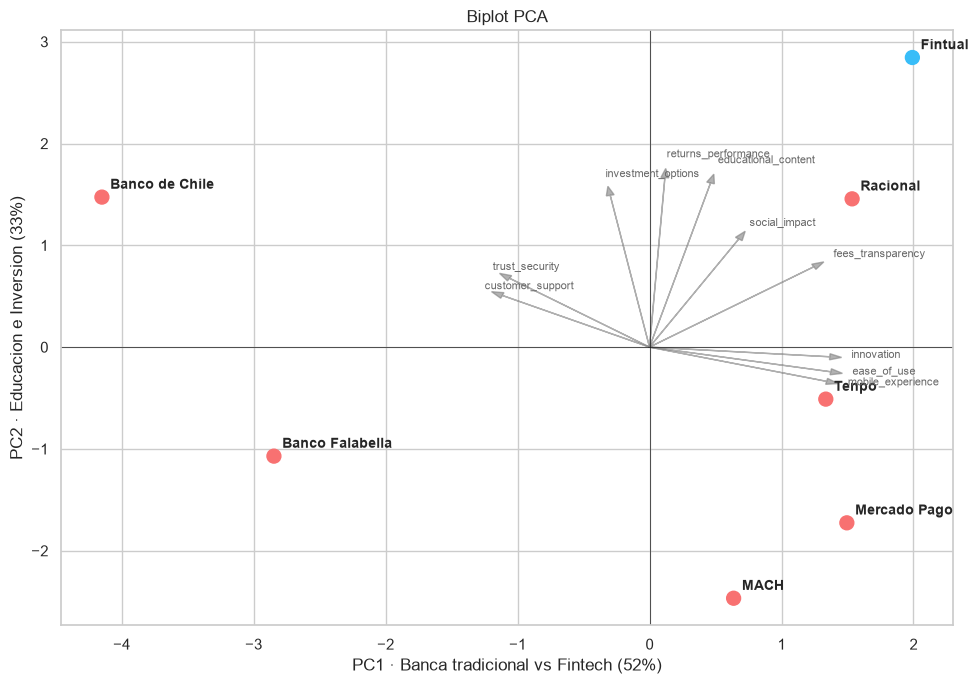

In [33]:
def biplot(scores, cargas, etiquetas, extra=None, titulo="Biplot PCA"):
    fig, ax = plt.subplots(figsize=(10, 7))
    
    # Celeste claro para Fintual y rojo claro para los competidores
    colores = ["#38bdf8" if m == "Fintual" else "#f87171" for m in etiquetas]
    ax.scatter(scores[:, 0], scores[:, 1], s=100, color=colores)
    
    for i, m in enumerate(etiquetas):
        ax.annotate(m, (scores[i, 0], scores[i, 1]), xytext=(6, 6), textcoords="offset points", fontsize=10, weight="bold")
    
    k = 3.2
    for a in cargas.index:
        ax.arrow(0, 0, cargas.loc[a, "PC1"] * k, cargas.loc[a, "PC2"] * k, color="gray", alpha=.6, head_width=.06)
        ax.text(cargas.loc[a, "PC1"] * k * 1.12, cargas.loc[a, "PC2"] * k * 1.12, a, color="dimgray", fontsize=8)
    
    if extra is not None:
        for nombre, (x, y) in extra.iterrows():
            ax.scatter(x, y, marker="*", s=260, color="crimson")
            ax.annotate(f"Ideal: {nombre}", (x, y), xytext=(6, -12), textcoords="offset points", color="crimson", fontsize=9)
    
    ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
    ax.set_xlabel(f"PC1 · Banca tradicional vs Fintech ({pca.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 · Educacion e Inversion ({pca.explained_variance_ratio_[1]:.0%})")
    ax.set_title(titulo); plt.tight_layout(); plt.show()

biplot(scores_pca, df_cargas, perception_by_brand.index)

In [34]:
# 1. Distancias euclidianas entre todas las marcas en el espacio original (10 dimensiones estandarizadas)
d_orig = pdist(data_scaled)

# 2. Correlación de Pearson entre distancias originales y distancias en PCA con 3 componentes
correlacion_pca3 = np.corrcoef(d_orig, pdist(scores_pca))[0, 1]

# 3. Correlación de Pearson con 2 componentes (el espacio proyectado en el Biplot)
correlacion_pca2 = np.corrcoef(d_orig, pdist(scores_pca[:, :2]))[0, 1]

# 4. Resultados formateados a 3 decimales
print(f"Correlación distancias originales vs PCA (3 componentes): {correlacion_pca3:.3f}")
print(f"Correlación distancias originales vs PCA (2 componentes / Biplot): {correlacion_pca2:.3f}")

Correlación distancias originales vs PCA (3 componentes): 0.997
Correlación distancias originales vs PCA (2 componentes / Biplot): 0.962


La correlación entre las distancias originales y el espacio de 3 componentes de PCA es 0,997, un valor superior a 0,8, lo que indica que las distancias originales se conservan adecuadamente. Con 2 componentes también se preservan bien (0,962 > 0,8), aunque el ajuste es ligeramente inferior al obtenido con 3 componentes.

## Parte 3.3: MDS y comparación de métodos  

Stress-1 de Kruskal: 0.116
Correlación distancias originales vs MDS: 0.958


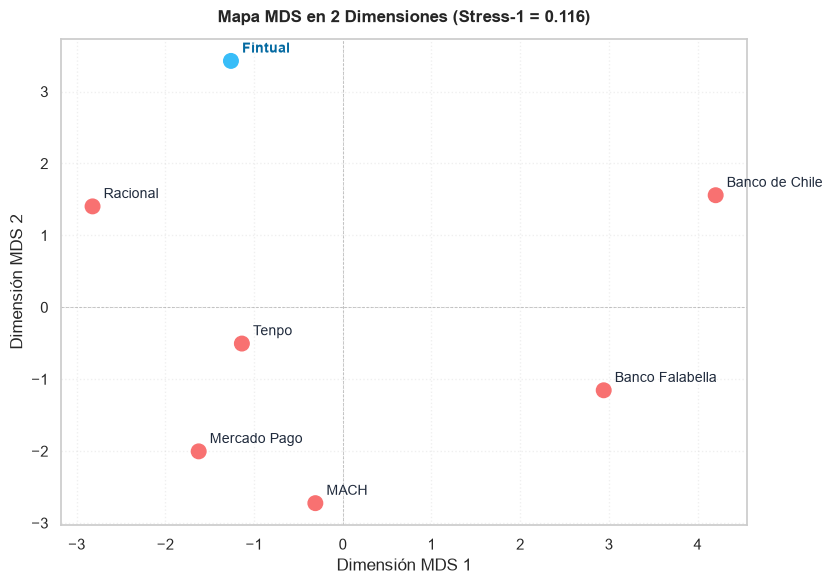

In [35]:
# 1. Ajuste del modelo MDS (configuración obligatoria de la pauta)
coordenadas_mds = mds.fit_transform(data_scaled)

# 2. Correlación de distancias originales vs distancias en el mapa MDS
correlacion_mds = np.corrcoef(d_orig, pdist(coordenadas_mds))[0, 1]
stress_mds = mds.stress_

print(f"Stress-1 de Kruskal: {stress_mds:.3f}")
print(f"Correlación distancias originales vs MDS: {correlacion_mds:.3f}")

# 3. Visualización del Mapa Perceptual MDS (2D)
fig, ax = plt.subplots(figsize=(8.5, 6))

# Colores consistentes: celeste claro para Fintual, rojo claro para competidores
colores_mds = ["#38bdf8" if m == "Fintual" else "#f87171" for m in perception_by_brand.index]
ax.scatter(coordenadas_mds[:, 0], coordenadas_mds[:, 1], s=110, color=colores_mds, zorder=3)

for i, marca in enumerate(perception_by_brand.index):
    peso = "bold" if marca == "Fintual" else "normal"
    color_texto = "#0369a1" if marca == "Fintual" else "#1e293b"
    ax.annotate(
        marca, 
        (coordenadas_mds[i, 0], coordenadas_mds[i, 1]), 
        xytext=(8, 6), 
        textcoords="offset points", 
        fontsize=10, 
        weight=peso,
        color=color_texto
    )

# Líneas de referencia y formato
ax.axhline(0, color="gray", linestyle="--", lw=0.6, alpha=0.5)
ax.axvline(0, color="gray", linestyle="--", lw=0.6, alpha=0.5)
ax.set_title(f"Mapa MDS en 2 Dimensiones (Stress-1 = {stress_mds:.3f})", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Dimensión MDS 1")
ax.set_ylabel("Dimensión MDS 2")
ax.grid(True, linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()


##### Diagnóstico de Stress-1 de Kruskal y Preservación de Distancias
El valor obtenido es de 0.116 (0.10 ≤ 0.116 ≤ 0.20). Este nivel de estrés se clasifica como débil (interpretar con cautela), indicando que forzar la reducción de 10 dimensiones a 2 en MDS introduce ciertas tensiones o distorsiones geométricas.


Correlación de distancias: La correlación de Pearson entre las distancias originales y las distancias MDS es de 0.958 (> 0.80), lo que refleja una buena preservación global de la proximidad entre pares de marcas.

##### Consistencia entre Mapas (PCA vs. MDS)
Banca tradicional: Banco de Chile y Banco Falabella se agrupan en un cuadrante independiente, aislados del resto.

Fintech de inversión: Fintual y Racional se posicionan juntos en el polo de gestión patrimonial.

Billeteras digitales: Tenpo, MACH y Mercado Pago forman un cluster compacto asociado a transaccionalidad cotidiana.

#### Metodo recomendado para fintual
Con el diagnóstico realizado previamente y el posicionamiento de Fintual Card, se recomienda utilizar PCA por las siguientes razones:

- Las correlaciones entre distancias en PCA, tanto con 2 como con 3 componentes, son superiores a las obtenidas con MDS.

- PCA permite interpretar sus ejes, pues éstos corresponden a las cargas factoriales de los atributos, lo que facilita tanto la interpretación como la toma de decisiones. Como desventaja, en PCA se pierde la capacidad de observar cada atributo de forma individual, sin embargo, los atributos pueden seguir interpretándose como un conjunto bien definido.

##### Competidores de fintual
En el grafico de PCA de dos dimensiones, Racional es la marca más cercana a Fintual. Banco de chile es el competidor en el cuadrante de banca tradicional e inversiones. Por ultimo Tenpo y Mercado pago son la competencia en Fintech, que solo se enfocan por el momento a las transacciones cotidianas.


## Parte 3.4: Lectura de marketing del mapa 

In [37]:
# Unir la encuesta de percepción con los segmentos asignados en la Parte 2
perc_seg = fintual_percepcion.merge(df_completo[["user_id", "segmento"]], on="user_id")
# Promedio de percepción por Segmento y Marca en los 10 atributos
cruce_segmentos = (
    perc_seg.groupby(["segmento", "brand"])[perception_columns]
    .mean()
    .round(2))
# Vista focalizada en los dos segmentos prioritarios para Fintual Card:
#    - Profesionales en Construcción (Target Primario: mayor capacidad de gasto)
#    - Nativos Digitales Emergentes (Target Secundario: alta transaccionalidad)
marcas_clave = ["Fintual", "Banco de Chile", "Mercado Pago", "Racional"]
segmentos_evaluar = ["Profesionales en Construcción", "Nativos Digitales Emergentes"]

cruce_foco = cruce_segmentos.loc[(segmentos_evaluar, marcas_clave), :]
display(cruce_foco)

ease_of_use  fees_transparency  investment_options  customer_support  mobile_experience  educational_content  trust_security  returns_performance  social_impact  innovation
segmento                      brand                                                                                                                                                                                       
Profesionales en Construcción Fintual                6.04               6.26                5.01              4.54               5.86                 6.13            5.47                 5.29           5.48        5.63
                              Banco de Chile         4.56               3.61                5.55              5.56               4.75                 4.18            6.28                 4.99           4.12        3.90
                              Mercado Pago           6.18               4.66                3.62              4.35               6.25                 3.48            5.25                 4.12           4.26        5.86
                              Racional               5.70               5.46                6.08              4.26               5.93                 4.87            4.87                 5.57           3.92        6.00
Nativos Digitales Emergentes  Fintual                5.97               6.26                5.01              4.48               5.86                 6.17            5.52                 5.34           5.46        5.54
                              Banco de Chile         4.20               3.64                5.59              5.57               4.41                 4.28            5.91                 5.03           4.11        3.51
                              Mercado Pago           6.45               4.74                3.60              4.41               6.52                 3.37            5.33                 4.13           4.32        6.24
                              Racional               5.77               5.50                6.13              4.23               5.92                 4.93            4.99                 5.62           3.97        5.99

In [ ]:
# Cálculo de brechas
for seg in segmentos_evaluar:
    tabla_seg = cruce_segmentos.loc[seg]
    
    # Diferencias directas: valor positivo = ventaja Fintual, negativo = rezago Fintual
    df_brechas = pd.DataFrame({
        "Dif. vs Banco de Chile": (tabla_seg.loc["Fintual"] - tabla_seg.loc["Banco de Chile"]).round(2),
        "Dif. vs Mercado Pago":   (tabla_seg.loc["Fintual"] - tabla_seg.loc["Mercado Pago"]).round(2),
        "Dif. vs Racional":          (tabla_seg.loc["Fintual"] - tabla_seg.loc["Racional"]).round(2)
    })
    
    print(f"\n--- Matriz de Brechas: Segmento '{seg}' ---")
    display(df_brechas)


--- Matriz de Brechas: Segmento 'Profesionales en Construcción' ---


,Dif. vs Banco de Chile,Dif. vs Mercado Pago,Dif. vs Racional
ease_of_use,1.48,-0.14,0.34
fees_transparency,2.65,1.60,0.80
investment_options,-0.54,1.39,-1.07
customer_support,-1.02,0.19,0.28
mobile_experience,1.11,-0.39,-0.07
educational_content,1.95,2.65,1.26
trust_security,-0.81,0.22,0.60
returns_performance,0.30,1.17,-0.28
social_impact,1.36,1.22,1.56
innovation,1.73,-0.23,-0.37



--- Matriz de Brechas: Segmento 'Nativos Digitales Emergentes' ---


,Dif. vs Banco de Chile,Dif. vs Mercado Pago,Dif. vs Racional
ease_of_use,1.77,-0.48,0.20
fees_transparency,2.62,1.52,0.76
investment_options,-0.58,1.41,-1.12
customer_support,-1.09,0.07,0.25
mobile_experience,1.45,-0.66,-0.06
educational_content,1.89,2.80,1.24
trust_security,-0.39,0.19,0.53
returns_performance,0.31,1.21,-0.28
social_impact,1.35,1.14,1.49
innovation,2.03,-0.70,-0.45


Las ventajas competitivas de Fintual son la transparencia en los cobros (fees_transparency = 6,26); es el líder en ambos segmentos de clientes.
La educación financiera (educational_content = 6,13 y 6,17) también es líder en los dos segmentos, destacándose principalmente por contar con una página web y un blog donde publica noticias de forma activa. A sus suscriptores les envía boletines con información actual; el canal se denomina Fintualist.
Fintual lidera en impacto social en ambos segmentos y ocupa la segunda posición en facilidad de uso.

En comparación con Banco de Chile, que se sitúa en el polo opuesto, Fintual queda rezagada en confianza y seguridad y en atención al cliente. La diferencia respectiva es de ‑0,39 puntos en confianza y seguridad en los nativos digitales emergentes y -0.81 en los Profesionales en Construcción. ‑1,09 puntos en atención al cliente  en los nativos digitales y -1.02 en los Profesionales en Construcción. y ‑0,58 puntos en opciones de inversión en los nativos digitales y -0.54 en los Profesionales en Construcción.

En relación con Mercado Pago, Fintual se queda detrás en facilidad de uso, experiencia en la aplicación y en innovación.

Finalmente, frente a Racional, que es el competidor directo, Fintual muestra desventajas en opciones de inversión (Racional permite comprar acciones y ETFs, mientras que Fintual, aunque también lo hace, lo promociona poco y su origen es como corredora de fondos y no de bolsa). Además, Fintual queda por detrás en innovación y en retornos.

Vector Objetivo: Atributos meta para Fintual Card


,ease_of_use,fees_transparency,investment_options,customer_support,mobile_experience,educational_content,trust_security,returns_performance,social_impact,innovation
Fintual Card (White Space),6.05,6.25,5.10,5.55,5.95,5.50,6.15,5.35,5.00,5.65



Coordenadas en el mapa -> PC1: 0.52, PC2: 2.94


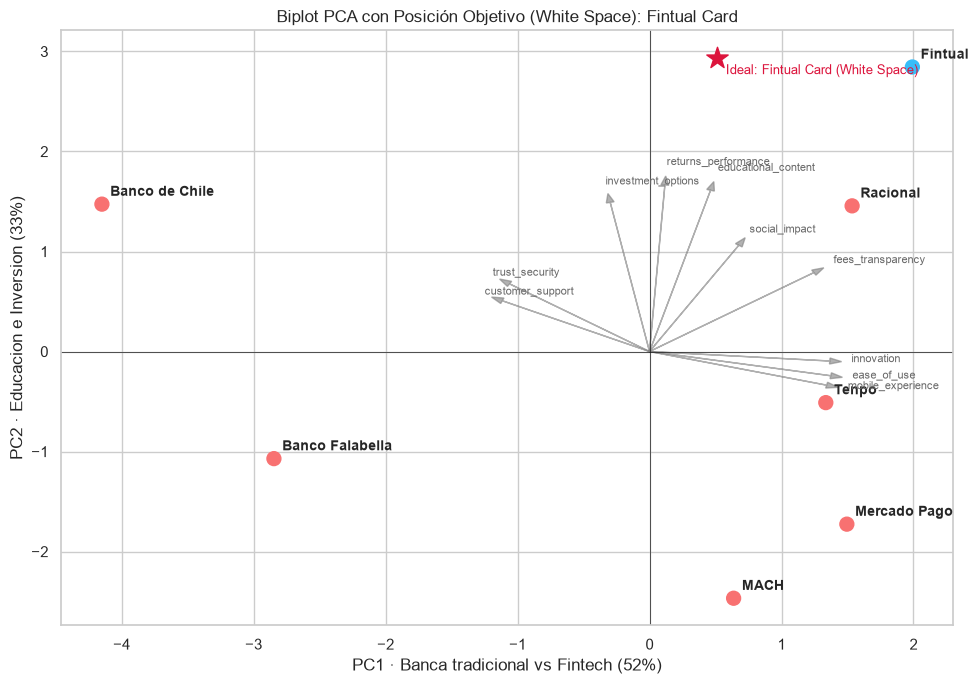


--- Distancia Euclidiana de cada competidor hacia la posición Fintual Card ---


,PC1 (Eje Fintech),PC2 (Eje Inversión),Distancia al White Space
brand,,,
Fintual,1.99,2.84,1.48
Racional,1.53,1.46,1.80
Tenpo,1.34,-0.51,3.55
Mercado Pago,1.50,-1.73,4.77
Banco de Chile,-4.15,1.47,4.89
Banco Falabella,-2.85,-1.07,5.23
MACH,0.64,-2.47,5.41


In [51]:
# Analsis de espacios vacios

# Definir el vector objetivo con los 10 atrinutos
objetivo_card = pd.DataFrame(
    {
        "ease_of_use":         [6.05],
        "fees_transparency":   [6.25],
        "investment_options":  [5.10],
        "customer_support":    [5.55],
        "mobile_experience":   [5.95],
        "educational_content": [5.50],
        "trust_security":      [6.15],
        "returns_performance": [5.35],
        "social_impact":       [5.00],
        "innovation":          [5.65],
    },
    index=["Fintual Card (White Space)"]
)[perception_columns]
print("Vector Objetivo: Atributos meta para Fintual Card")
display(objetivo_card)

# Proyección ortogonal del Vector Objetivo sobre el espacio PCA existente
#    (Importante: se estandariza con las medias/desviaciones originales de perception_by_brand)
scaler_pca = StandardScaler().fit(perception_by_brand)
objetivo_scaled = scaler_pca.transform(objetivo_card)

# Coordenadas 2D proyectadas (PC1, PC2)
objetivo_xy = pd.DataFrame(
    pca.transform(objetivo_scaled)[:, :2],
    index=objetivo_card.index,
    columns=["PC1", "PC2"]
)
print(f"\nCoordenadas en el mapa -> PC1: {objetivo_xy.iloc[0, 0]:.2f}, PC2: {objetivo_xy.iloc[0, 1]:.2f}")

# Graficar el Biplot incluyendo el White Space (Estrella roja)
biplot(
    scores_pca, 
    df_cargas, 
    perception_by_brand.index, 
    extra=objetivo_xy, 
    titulo="Biplot PCA con Posición Objetivo (White Space): Fintual Card"
)
# Cuantificación: Distancias euclidianas 2D desde las marcas hacia el White Space
marcas_2d = pd.DataFrame(scores_pca[:, :2], index=perception_by_brand.index, columns=["PC1", "PC2"])
distancias_al_objetivo = pd.DataFrame({
    "PC1 (Eje Fintech)": marcas_2d["PC1"].round(2),
    "PC2 (Eje Inversión)": marcas_2d["PC2"].round(2),
    "Distancia al White Space": [
        np.linalg.norm(marcas_2d.loc[m] - objetivo_xy.iloc[0]) for m in marcas_2d.index
    ]
}).sort_values("Distancia al White Space").round(2)
print("\n--- Distancia Euclidiana de cada competidor hacia la posición Fintual Card ---")
display(distancias_al_objetivo)

La definición del vector objetivo para Fintual Card surge estratégicamente para responder a las demandas insatisfechas de los dos segmentos que se tiene como objetivo: "Profesionales en Construcción" y "Nativos Digitales Emergentes".

Para posicionar la tarjeta en el espacio no cubierto del mapa, se definió un perfil meta de 10 atributos que preserva las fortalezas troncales de Fintual e iguala los estándares de seguridad y atención de la banca tradicional:

- fees_transparency [6.25]: Mantiene el liderazgo absoluto del mercado de Fintual (6.24) bajo una política de $0 comisiones ocultas.

  
- trust_security [6.15]: Sube de manera sustancial desde el 5.41 actual de Fintual hasta alcanzar el estándar de solidez percibida del Banco de Chile (6.19).

  
- customer_support [5.55]: Supera el rezago de Fintual (4.51) igualando la capacidad de respuesta y soporte de nivel bancario (Banco de Chile: 5.63).

  
- returns_performance [5.35]: Preserva el rendimiento de Fintual (5.35), asegurando que los saldos transaccionales generen rentabilidad diaria.

  
- ease_of_use [6.05]: Mantiene la simplicidad intuitiva de Fintual (6.02) frente al mercado general.

  
- mobile_experience [5.95]: Refuerza la experiencia en la aplicación móvil de Fintual (5.85) para aproximarse a los referentes de pago como Mercado Pago (6.34).

  
- innovation [5.65]: Refuerza el perfil vanguardista de Fintual (5.57) mediante tarjeta virtual inmediata y enrolamiento en billeteras móviles.

  
- investment_options [5.10]: Mantiene la oferta actual de fondos optimizados de Fintual (5.00), integrándolos directamente con el medio de pago.

  
- educational_content [5.50]: Se modera levemente (desde 6.16) al tratarse de un instrumento enfocado en la transaccionalidad cotidiana.

  
- social_impact [5.00]: Conserva un rol positivo y diferenciador en comparación con la banca tradicional (4.13).

Las coordenadas de la Fintual Card son PC1 = 0,52 y PC2 = 2,94. La tarjeta sigue ubicándose en la parte superior del gráfico, diferenciándose de las billeteras digitales, que sólo buscan transacciones tradicionales. El eje PC1 se desplaza hacia la izquierda, centrando la posición y cerrando la brecha de confianza y atención al cliente. Al visualizar la distancia de cada competidor al punto proyectado de Fintual Card, se confirma que ningún competidor ocupa ese espacio.
